## Setup and Dependencies

In [17]:
# Install uv for dependency management
%pip install -U uv

import platform
import subprocess

# Detect system architecture and CUDA availability
def is_apple_silicon():
    return platform.system() == "Darwin" and platform.machine() == "arm64"

def has_cuda():
    try:
        import torch
        return torch.cuda.is_available()
    except ImportError:
        # Try to check if nvidia-smi is available
        try:
            subprocess.check_output(['nvidia-smi'])
            return True
        except (subprocess.SubprocessError, FileNotFoundError):
            return False

# Install PyTorch and PyG packages based on detected system
if is_apple_silicon():
    print("Detected Apple Silicon - installing MPS-compatible PyTorch")
    !uv pip install torch torchvision torchaudio
    !uv pip install torch-geometric
    !uv pip install numpy scipy

elif has_cuda():
    print("Detected CUDA support - installing CUDA-compatible PyTorch")
    # Using a recent CUDA version that's likely to be compatible
    !uv pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

    # Install PyG with CUDA support
    !uv pip install torch-geometric
    !uv pip install torch-scatter torch-sparse torch-cluster torch-spline-conv -f https://data.pyg.org/whl/torch-2.0.0+cu118.html
    !uv pip install numpy scipy
else:
    print("No GPU acceleration detected - installing CPU-only versions")
    !uv pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu
    !uv pip install torch-geometric
    !uv pip install numpy scipy

!uv pip install matplotlib scikit-learn seaborn networkx umap-learn


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Detected Apple Silicon - installing MPS-compatible PyTorch
Audited 3 packages in 12ms
Audited 1 package in 2ms
Audited 2 packages in 1ms
Audited 5 packages in 2ms


## Import Libraries and Set up device

In [27]:
import torch
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set up device
device = None
if torch.cuda.is_available():
    device = torch.device('cuda')
    print("Using CUDA")
# elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
#     device = torch.device('mps')
#     print("Using Apple Silicon MPS")
else:
    device = torch.device('cpu')
    print("Using CPU")

plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 18,
    'axes.labelsize': 18,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16,
    'figure.titlesize': 20
})

Using CPU


## Load and Explore Dataset

Dataset: Cora
Number of nodes: 2708
Number of edges: 10556
Number of features: 1433
Number of classes: 7


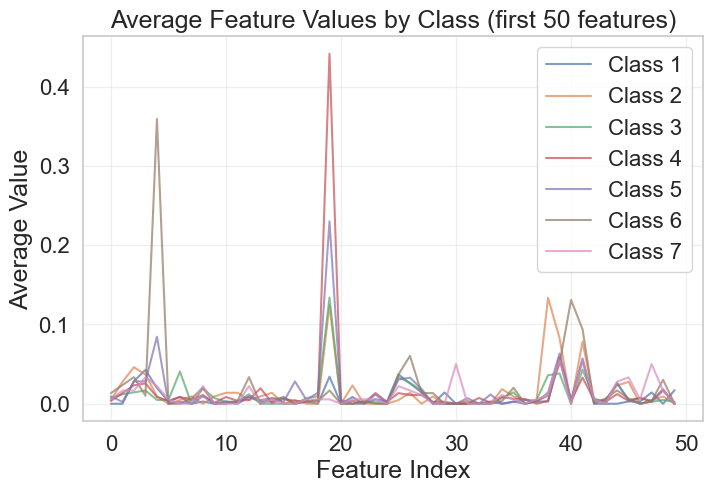

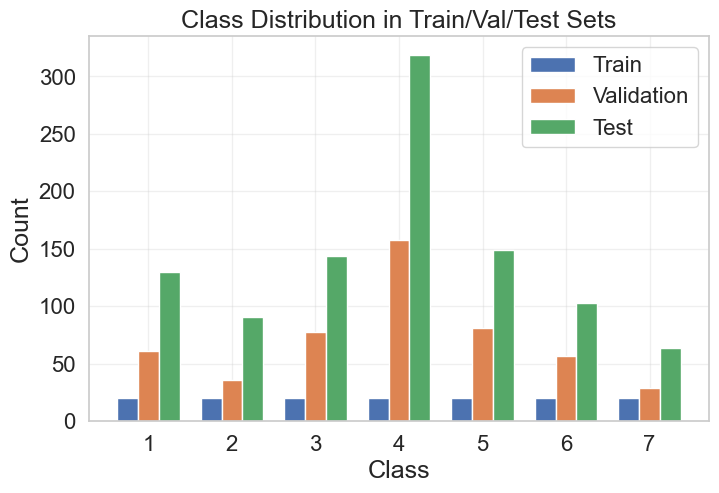

In [19]:
# Load the Cora dataset
dataset = Planetoid(root='/tmp/Cora', name='Cora')
data = dataset[0].to(device) # type: ignore

# Print dataset info
print(f"Dataset: {dataset.name}")
print(f"Number of nodes: {data.num_nodes}") # type: ignore
print(f"Number of edges: {data.num_edges}") # type: ignore
print(f"Number of features: {data.num_features}")
print(f"Number of classes: {dataset.num_classes}")

# Get node features
features = data.x.cpu().numpy()
labels = data.y.cpu().numpy()

# Compute average feature values for each class
class_features = []
for class_idx in range(dataset.num_classes):
    mask = labels == class_idx
    class_features.append(features[mask].mean(axis=0))

# Plot average feature patterns for each class
plt.figure(figsize=(8, 5))
for i, avg_features in enumerate(class_features):
    # Only plot first 50 features for clarity
    plt.plot(avg_features[:50], label=f'Class {i + 1}', alpha=0.7)

plt.title('Average Feature Values by Class (first 50 features)')
plt.xlabel('Feature Index')
plt.ylabel('Average Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Count instances of each class in train/val/test sets
train_counts = np.bincount(data.y[data.train_mask].cpu().numpy(), minlength=dataset.num_classes)
val_counts = np.bincount(data.y[data.val_mask].cpu().numpy(), minlength=dataset.num_classes)
test_counts = np.bincount(data.y[data.test_mask].cpu().numpy(), minlength=dataset.num_classes)

# Plot class distribution
plt.figure(figsize=(8, 5))
x = np.arange(dataset.num_classes)
width = 0.25

plt.bar(x - width, train_counts, width, label='Train')
plt.bar(x, val_counts, width, label='Validation')
plt.bar(x + width, test_counts, width, label='Test')

plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Class Distribution in Train/Val/Test Sets')
plt.xticks(x, [f'{i + 1}' for i in range(dataset.num_classes)])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Base Model Training and Visualization

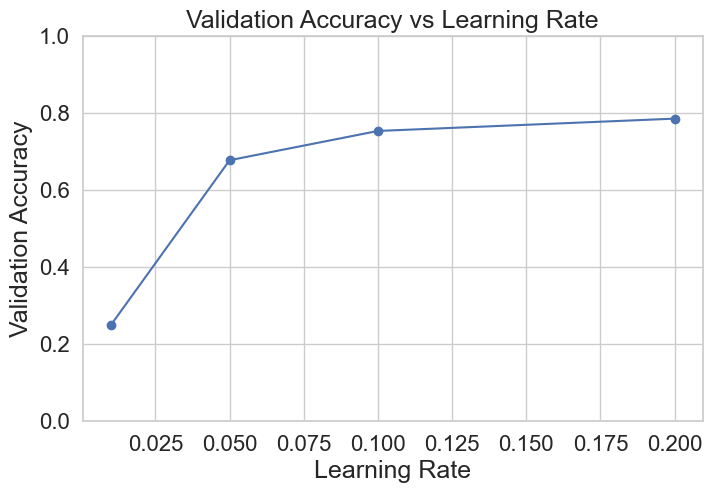

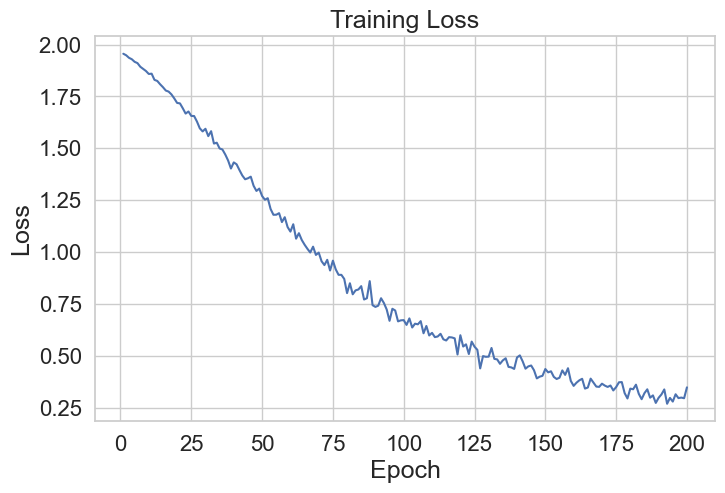

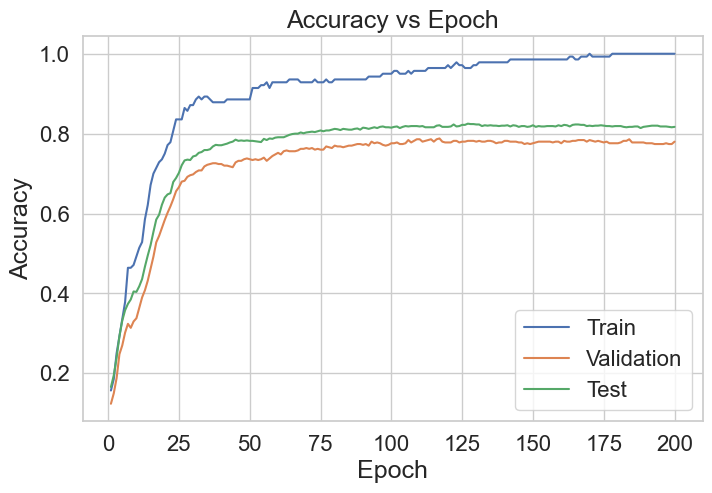

In [20]:
# Define GCN model
class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

# Search over learning rates
learning_rates = [0.01, 0.05, 0.1, 0.2]
lr_results = []

# print("\n=== Learning Rate Search ===")
for lr in learning_rates:
    model = GCN(in_channels=dataset.num_features, hidden_channels=16, out_channels=dataset.num_classes).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=1e-3)

    for epoch in range(200):
        model.train()
        optimizer.zero_grad()
        out = model(data)
        loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

    # evaluate over validation dataset
    model.eval()
    with torch.no_grad():
        logits = model(data)
        pred = logits[data.val_mask].max(1)[1]
        acc = pred.eq(data.y[data.val_mask]).sum().item() / data.val_mask.sum().item()

    # print(f"LR = {lr:.3f} -> Val Accuracy = {acc:.4f}")
    lr_results.append({'lr': lr, 'val_acc': acc})

best_result = max(lr_results, key=lambda x: x['val_acc'])
best_lr = best_result['lr']
# print(f"\nBest LR: {best_lr:.3f} with Val Acc: {best_result['val_acc']:.4f}")

# Plot learning rate vs accuracy
plt.figure(figsize=(8, 5))
sns.set_style("whitegrid")
plt.plot([r['lr'] for r in lr_results], [r['val_acc'] for r in lr_results], marker='o')
plt.xlabel('Learning Rate')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy vs Learning Rate')
plt.ylim(0, 1)
plt.grid(True)
plt.show()

# Final Training with Best LR
model = GCN(in_channels=dataset.num_features, hidden_channels=16, out_channels=dataset.num_classes).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=best_lr, weight_decay=1e-3)

epochs = []
losses = []
train_accs = []
val_accs = []
test_accs = []

# print("\n=== Training with Best LR ===")
for epoch in range(1, 201):
    model.train()
    optimizer.zero_grad()
    out = model(data)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        logits = model(data)
        train_acc = logits[data.train_mask].max(1)[1].eq(data.y[data.train_mask]).sum().item() / data.train_mask.sum().item()
        val_acc = logits[data.val_mask].max(1)[1].eq(data.y[data.val_mask]).sum().item() / data.val_mask.sum().item()
        test_acc = logits[data.test_mask].max(1)[1].eq(data.y[data.test_mask]).sum().item() / data.test_mask.sum().item()

    epochs.append(epoch)
    losses.append(loss.item())
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    test_accs.append(test_acc)

    # if epoch % 20 == 0:
        # print(f"Epoch {epoch:03d} | Loss: {loss.item():.4f} | Train: {train_acc:.4f} | Val: {val_acc:.4f} | Test: {test_acc:.4f}")

# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.show()

# Plot accuracy vs epoch (train, val, and test)
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accs, label='Train')
plt.plot(epochs, val_accs, label='Validation')
plt.plot(epochs, test_accs, label='Test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epoch')
plt.legend()
plt.show()

## Model Variation: Multiple Layers

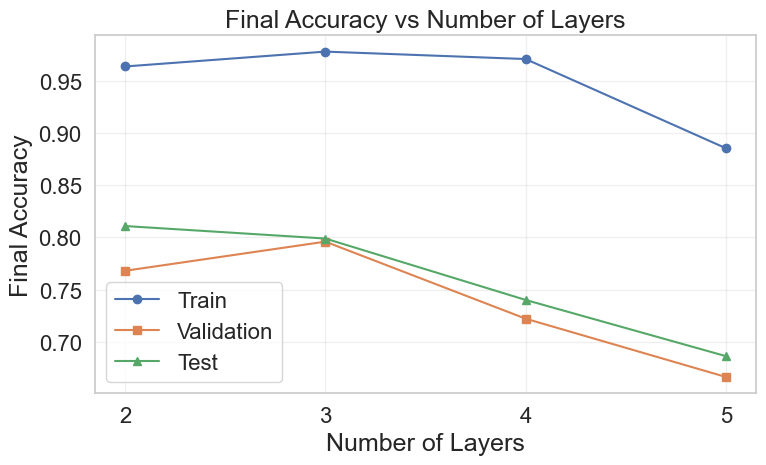

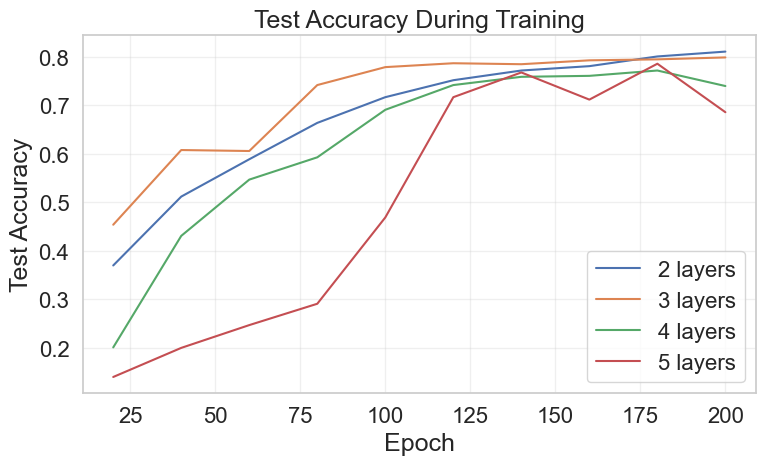

In [21]:
# GCN model with variable number of layers
class GCNMultiLayer(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers=2, dropout=0.5):
        super(GCNMultiLayer, self).__init__()
        self.num_layers = num_layers

        self.convs = torch.nn.ModuleList() # list to store layers

        self.convs.append(GCNConv(in_channels, hidden_channels))  # First layer
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(hidden_channels, hidden_channels)) # Hidden layers
        self.convs.append(GCNConv(hidden_channels, out_channels))  # Output layer

        self.dropout = torch.nn.Dropout(dropout) # not hard coding dropout

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        for i in range(self.num_layers - 1):
            x = self.convs[i](x, edge_index)
            x = F.relu(x)
            x = self.dropout(x)
        x = self.convs[-1](x, edge_index)
        return F.log_softmax(x, dim=1)

# search for best lr
def find_best_lr(num_layers, candidate_lrs=[0.01, 0.05, 0.1, 0.2], epochs=200):
    val_results = []

    for lr in candidate_lrs:
        model = GCNMultiLayer(in_channels=dataset.num_features, hidden_channels=16, out_channels=dataset.num_classes, num_layers=num_layers).to(device)
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=1e-3)

        for epoch in range(1, epochs + 1):
            model.train()
            optimizer.zero_grad()
            out = model(data)
            loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(data)
            val_acc = logits[data.val_mask].max(1)[1].eq(data.y[data.val_mask]).float().mean().item()

        val_results.append({'lr': lr, 'val_acc': val_acc})
        # print(f"[LR Search] Layers: {num_layers}, LR: {lr}, Val Acc: {val_acc:.4f}")

    # Pick best LR by val acc
    best = max(val_results, key=lambda x: x['val_acc'])
    # print(f"> Best LR for {num_layers} layers: {best['lr']:.3f} (Val Acc: {best['val_acc']:.4f})")
    return best['lr']

# Train and evaluate for layer depths using best LR
def train_and_evaluate_layers_with_lr(max_layers=5, epochs=200):
    results = []

    for num_layers in range(2, max_layers + 1):
        best_lr = find_best_lr(num_layers)
        model = GCNMultiLayer(in_channels=dataset.num_features, hidden_channels=16, out_channels=dataset.num_classes, num_layers=num_layers).to(device)
        optimizer = torch.optim.SGD(model.parameters(), lr=best_lr, weight_decay=1e-3)

        train_accs, val_accs, test_accs = [], [], []

        for epoch in range(1, epochs + 1):
            model.train()
            optimizer.zero_grad()
            out = model(data)
            loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
            loss.backward()
            optimizer.step()

            if epoch % 20 == 0 or epoch == epochs:
                model.eval()
                with torch.no_grad():
                    logits = model(data)
                    train_acc = logits[data.train_mask].max(1)[1].eq(data.y[data.train_mask]).float().mean().item()
                    val_acc = logits[data.val_mask].max(1)[1].eq(data.y[data.val_mask]).float().mean().item()
                    test_acc = logits[data.test_mask].max(1)[1].eq(data.y[data.test_mask]).float().mean().item()

                train_accs.append(train_acc)
                val_accs.append(val_acc)
                test_accs.append(test_acc)

                # print(f"Layers: {num_layers}, Epoch: {epoch:03d}, "
                #       f"Train: {train_acc:.4f}, Val: {val_acc:.4f}, Test: {test_acc:.4f}")

        results.append({
            'num_layers': num_layers,
            'final_train_acc': train_accs[-1],
            'final_val_acc': val_accs[-1],
            'final_test_acc': test_accs[-1],
            'train_accs': train_accs,
            'val_accs': val_accs,
            'test_accs': test_accs
        })

    return results

# plot results
def plot_layer_comparison(results):

    # Final acc by layers
    plt.figure(figsize=(8, 5))
    layers = [r['num_layers'] for r in results]
    plt.plot(layers, [r['final_train_acc'] for r in results], 'o-', label='Train')
    plt.plot(layers, [r['final_val_acc'] for r in results], 's-', label='Validation')
    plt.plot(layers, [r['final_test_acc'] for r in results], '^-', label='Test')
    plt.xlabel('Number of Layers')
    plt.ylabel('Final Accuracy')
    plt.title('Final Accuracy vs Number of Layers')
    plt.grid(True, alpha=0.3)
    plt.xticks(layers)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Test acc during training
    plt.figure(figsize=(8, 5))
    epochs = list(range(20, 201, 20))
    for r in results:
        plt.plot(epochs, r['test_accs'], label=f'{r["num_layers"]} layers')
    plt.xlabel('Epoch')
    plt.ylabel('Test Accuracy')
    plt.title('Test Accuracy During Training')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Run comparison
layer_results = train_and_evaluate_layers_with_lr(max_layers=5)
plot_layer_comparison(layer_results)

## Model Variation: Different Probabilites of Dropout

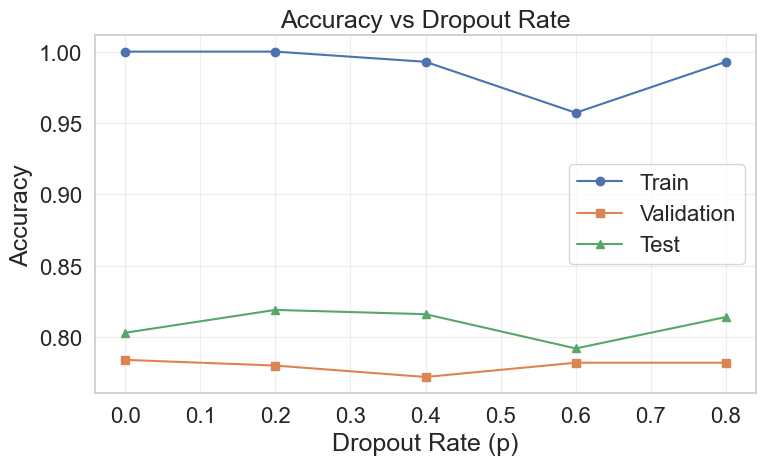

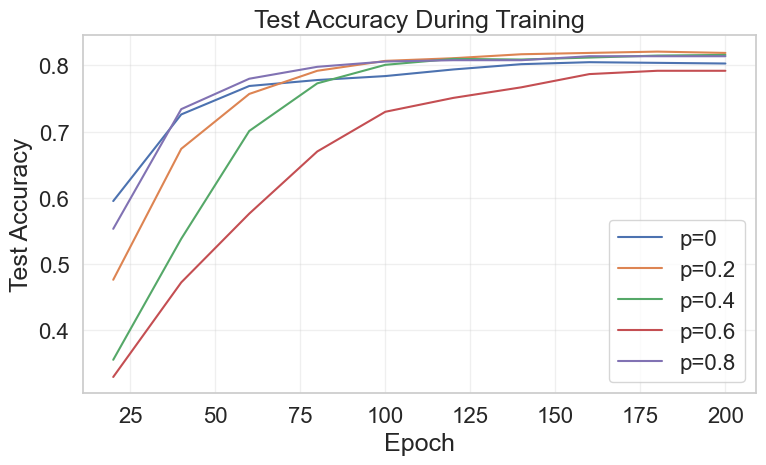

In [22]:
class GCNWithDropout(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout):
        super(GCNWithDropout, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = torch.nn.Dropout(dropout)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.dropout(x)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

# Find best LR for a given dropout
def find_best_lr(dropout, candidate_lrs=[0.01, 0.05, 0.1, 0.2], epochs=200):
    val_results = []

    for lr in candidate_lrs:
        model = GCNWithDropout(in_channels=dataset.num_features, hidden_channels=16, out_channels=dataset.num_classes, dropout=dropout).to(device)
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=1e-3)

        for epoch in range(1, epochs + 1):
            model.train()
            optimizer.zero_grad()
            out = model(data)
            loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(data)
            val_acc = logits[data.val_mask].max(1)[1].eq(data.y[data.val_mask]).float().mean().item()

        val_results.append({'lr': lr, 'val_acc': val_acc})
        # print(f"[LR Search] Dropout: {dropout}, LR: {lr}, Val Acc: {val_acc:.4f}")

    # Pick best LR by val acc
    best = max(val_results, key=lambda x: x['val_acc'])
    # print(f"> Best LR for {dropout} dropout: {best['lr']:.3f} (Val Acc: {best['val_acc']:.4f})")
    return best['lr']


def train_and_evaluate_dropout_with_lr(dropout_rates, epochs=200):
    results = []

    for p in dropout_rates:
        best_lr = find_best_lr(p)
        model = GCNWithDropout(in_channels=dataset.num_node_features, hidden_channels=16, out_channels=dataset.num_classes, dropout=p)
        optimizer = torch.optim.SGD(model.parameters(), lr=best_lr, weight_decay=1e-3)

        train_accs, val_accs, test_accs = [], [], []

        for epoch in range(1, epochs + 1):
            model.train()
            optimizer.zero_grad()
            out = model(data)
            loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
            loss.backward()
            optimizer.step()

            if epoch % 20 == 0 or epoch == epochs:
                model.eval()
                with torch.no_grad():
                    logits = model(data)
                    train_acc = logits[data.train_mask].max(1)[1].eq(data.y[data.train_mask]).float().mean().item()
                    val_acc = logits[data.val_mask].max(1)[1].eq(data.y[data.val_mask]).float().mean().item()
                    test_acc = logits[data.test_mask].max(1)[1].eq(data.y[data.test_mask]).float().mean().item()

                train_accs.append(train_acc)
                val_accs.append(val_acc)
                test_accs.append(test_acc)

                # print(f"Dropout: {p}, Epoch: {epoch:03d}, "
                #       f"Train: {train_acc:.4f}, Val: {val_acc:.4f}, Test: {test_acc:.4f}")

        results.append({
            'dropout': p,
            'final_train_acc': train_accs[-1],
            'final_val_acc': val_accs[-1],
            'final_test_acc': test_accs[-1],
            'train_accs': train_accs,
            'val_accs': val_accs,
            'test_accs': test_accs
        })

    return results


def plot_dropout_comparison(results):

    ps = [r['dropout'] for r in results]
    train_accs = [r['final_train_acc'] for r in results]
    val_accs = [r['final_val_acc'] for r in results]
    test_accs = [r['final_test_acc'] for r in results]

    # Final acc by dropout rate
    plt.figure(figsize=(8, 5))
    plt.plot(ps, train_accs, 'o-', label='Train')
    plt.plot(ps, val_accs, 's-', label='Validation')
    plt.plot(ps, test_accs, '^-', label='Test')
    plt.xlabel('Dropout Rate (p)')
    plt.ylabel('Accuracy')
    plt.title('Accuracy vs Dropout Rate')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Test acc during training
    plt.figure(figsize=(8, 5))
    epochs = list(range(20, 201, 20))
    for r in results:
        plt.plot(epochs, r['test_accs'], label=f'p={r["dropout"]}')
    plt.xlabel('Epoch')
    plt.ylabel('Test Accuracy')
    plt.title('Test Accuracy During Training')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Run comparison
dropout_rates = [0, 0.2, 0.4, 0.6, 0.8]
dropout_results = train_and_evaluate_dropout_with_lr(dropout_rates)
plot_dropout_comparison(dropout_results)


## Model Variation: Different Optimizers

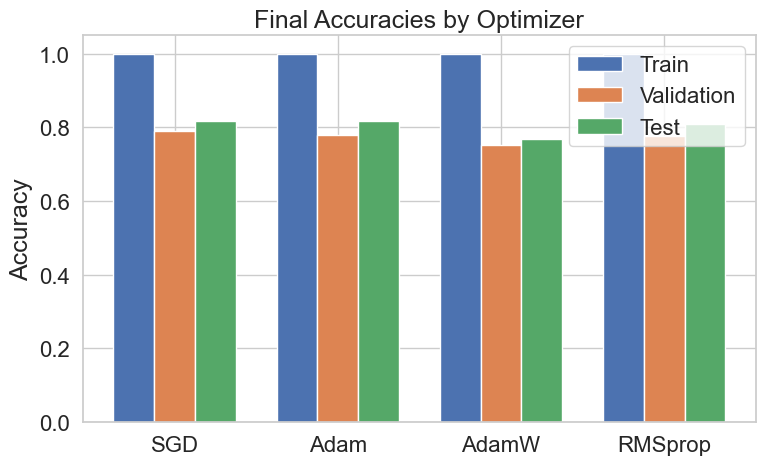

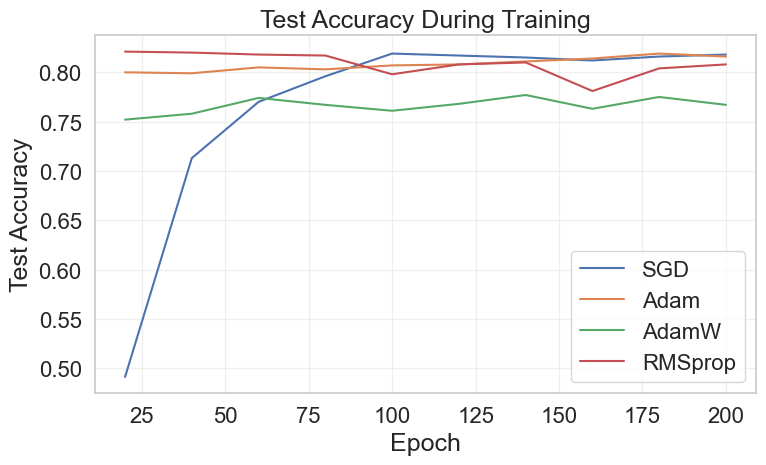

In [23]:
class GCNdiffOptim(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout):
        super(GCNdiffOptim, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = torch.nn.Dropout(dropout)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.dropout(x)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

optimizers = [
    ('SGD', torch.optim.SGD),
    ('Adam', torch.optim.Adam),
    ('AdamW', torch.optim.AdamW),
    ('RMSprop', torch.optim.RMSprop),
]

def find_best_lr_for_optimizer(opt_class, dropout=0.5, candidate_lrs=[0.01, 0.05, 0.1, 0.2], epochs=200):
    val_results = []
    for lr in candidate_lrs:
        model = GCNdiffOptim(in_channels=dataset.num_node_features, hidden_channels=16, out_channels=dataset.num_classes, dropout=dropout).to(device)
        optimizer = opt_class(model.parameters(), lr=lr, weight_decay=1e-3)

        for _ in range(epochs):
            model.train()
            optimizer.zero_grad()
            out = model(data)
            loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(data)
            val_acc = logits[data.val_mask].max(1)[1].eq(data.y[data.val_mask]).float().mean().item()
        val_results.append({'lr': lr, 'val_acc': val_acc})
        # print(f"[LR Search] Optimizer: {opt_class.__name__}, LR: {lr}, Val Acc: {val_acc:.4f}")

    best = max(val_results, key=lambda x: x['val_acc'])
    # print(f"> Best LR for {opt_class.__name__}: {best['lr']:.4f} (Val Acc: {best['val_acc']:.4f})")
    return best['lr']

def train_and_evaluate_optimizers(optimizers, dropout=0.5, epochs=200):
    results = []
    for name, opt_class in optimizers:
        best_lr = find_best_lr_for_optimizer(opt_class, dropout)
        model = GCNdiffOptim(in_channels=dataset.num_node_features, hidden_channels=16, out_channels=dataset.num_classes, dropout=dropout).to(device)
        optimizer = opt_class(model.parameters(), lr=best_lr, weight_decay=1e-3)

        train_accs, val_accs, test_accs = [], [], []
        for epoch in range(1, epochs + 1):
            model.train()
            optimizer.zero_grad()
            out = model(data)
            loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
            loss.backward()
            optimizer.step()

            if epoch % 20 == 0 or epoch == epochs:
                model.eval()
                with torch.no_grad():
                    logits = model(data)
                    train_acc = logits[data.train_mask].max(1)[1].eq(data.y[data.train_mask]).float().mean().item()
                    val_acc = logits[data.val_mask].max(1)[1].eq(data.y[data.val_mask]).float().mean().item()
                    test_acc = logits[data.test_mask].max(1)[1].eq(data.y[data.test_mask]).float().mean().item()
                train_accs.append(train_acc)
                val_accs.append(val_acc)
                test_accs.append(test_acc)
                # print(f"Optimizer: {name}, Epoch: {epoch:03d}, Train: {train_acc:.4f}, Val: {val_acc:.4f}, Test: {test_acc:.4f}")

        results.append({
            'optimizer': name,
            'final_train_acc': train_accs[-1],
            'final_val_acc': val_accs[-1],
            'final_test_acc': test_accs[-1],
            'train_accs': train_accs,
            'val_accs': val_accs,
            'test_accs': test_accs
        })
    return results

def plot_optimizer_comparison(results):

    names = [r['optimizer'] for r in results]
    train_accs = [r['final_train_acc'] for r in results]
    val_accs = [r['final_val_acc'] for r in results]
    test_accs = [r['final_test_acc'] for r in results]

    # Final acc by optimizer
    plt.figure(figsize=(8, 5))
    bar_width = 0.25
    x = range(len(names))
    plt.bar(x, train_accs, width=bar_width, label='Train')
    plt.bar([p + bar_width for p in x], val_accs, width=bar_width, label='Validation')
    plt.bar([p + 2 * bar_width for p in x], test_accs, width=bar_width, label='Test')
    plt.xticks([p + bar_width for p in x], names)
    plt.ylabel('Accuracy')
    plt.title('Final Accuracies by Optimizer')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Test acc during training
    plt.figure(figsize=(8, 5))
    epochs = list(range(20, 201, 20))
    for r in results:
        plt.plot(epochs, r['test_accs'], label=r['optimizer'])
    plt.xlabel('Epoch')
    plt.ylabel('Test Accuracy')
    plt.title('Test Accuracy During Training')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


optimizer_results = train_and_evaluate_optimizers(optimizers)
plot_optimizer_comparison(optimizer_results)


## Conclusion and Analysis

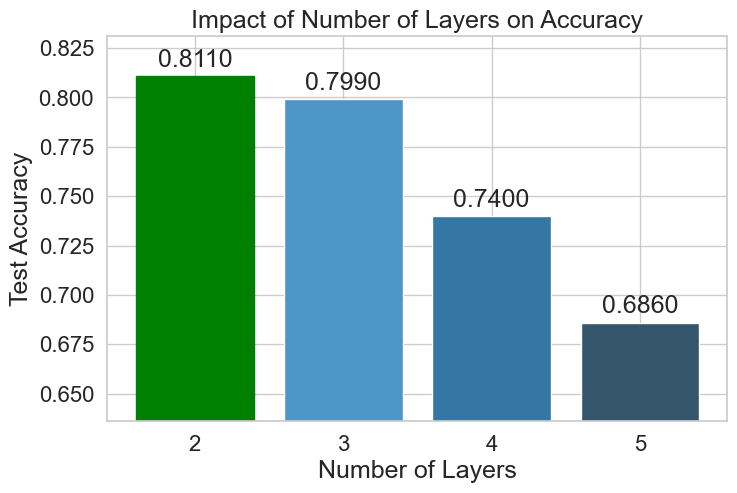

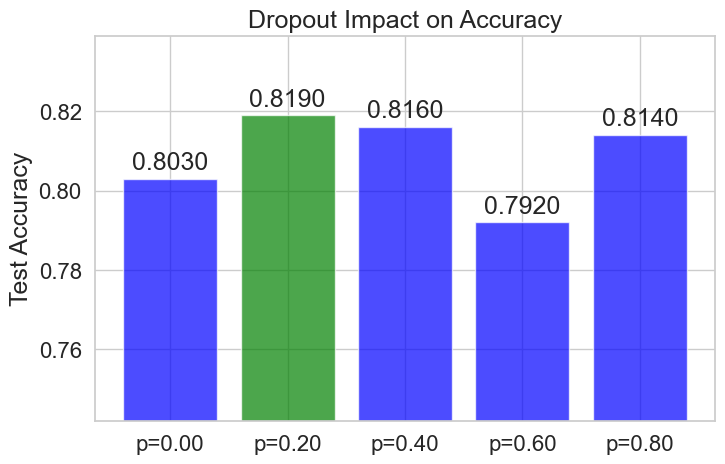

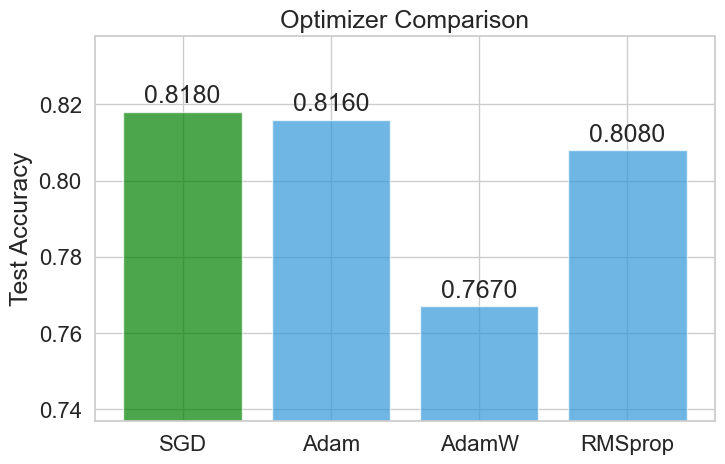

In [28]:
def summarize_experiments(layer_results, dropout_results, optimizer_results):
    # print("=== EXPERIMENT SUMMARY ===")

    # 1. Layer comparison
    best_layer = max(layer_results, key=lambda x: x['final_test_acc'])
    # print(f"\nBest number of layers: {best_layer['num_layers']} with test accuracy: {best_layer['final_test_acc']:.4f}")

    # 2. Dropout comparison
    best_dropout_result = max(dropout_results, key=lambda x: x['final_test_acc'])
    # print(f"\nBest dropout: p={best_dropout_result['dropout']:.2f} with test accuracy: {best_dropout_result['final_test_acc']:.4f}")

    # 3. Optimizer comparison
    best_optimizer_result = max(optimizer_results, key=lambda x: x['final_test_acc'])
    # print(f"\nBest optimizer: {best_optimizer_result['optimizer']} with test accuracy: {best_optimizer_result['final_test_acc']:.4f}")


    return best_layer, best_dropout_result, best_optimizer_result


best_layer, best_dropout_result, best_optimizer_result = summarize_experiments(layer_results, dropout_results, optimizer_results)


# 1. Layers comparison plot
# sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
layers = [result['num_layers'] for result in layer_results]
accuracies = [result['final_test_acc'] for result in layer_results]
bars = plt.bar(layers, accuracies, color=sns.color_palette("Blues_d", len(layers)))
plt.xlabel('Number of Layers')
plt.ylabel('Test Accuracy')
plt.title('Impact of Number of Layers on Accuracy')
plt.ylim(min(accuracies) - 0.05, max(accuracies) + 0.02)
plt.xticks(layers)
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}', xy=(bar.get_x() + bar.get_width()/2, height), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom')
bars[layers.index(best_layer['num_layers'])].set_color('green')
plt.show()

# 2. Dropout comparison plot
plt.figure(figsize=(8, 5))
dropout_ps = [result['dropout'] for result in dropout_results]
dropout_accs = [result['final_test_acc'] for result in dropout_results]
colors = ['blue'] * len(dropout_ps)
best_dropout_idx = dropout_accs.index(max(dropout_accs))
colors[best_dropout_idx] = 'green'
bars = plt.bar([f'p={p:.2f}' for p in dropout_ps], dropout_accs, color=colors, alpha=0.7)
plt.ylabel('Test Accuracy')
plt.title('Dropout Impact on Accuracy')
plt.ylim(min(dropout_accs) - 0.05, max(dropout_accs) + 0.02)
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}', xy=(bar.get_x() + bar.get_width()/2, height), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom')
plt.show()

# 3. Optimizer comparison plot
plt.figure(figsize=(8, 5))
opt_names = [r['optimizer'] for r in optimizer_results]
opt_acc = [r['final_test_acc'] for r in optimizer_results]
colors = ['#3498db'] * len(opt_names)
best_opt_name = max(optimizer_results, key=lambda r: r['final_test_acc'])['optimizer']
colors[opt_names.index(best_opt_name)] = 'green'
bars = plt.bar(opt_names, opt_acc, color=colors, alpha=0.7)
plt.ylabel('Test Accuracy')
plt.title('Optimizer Comparison')
plt.ylim(min(opt_acc) - 0.03, max(opt_acc) + 0.02)
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}', xy=(bar.get_x() + bar.get_width()/2, height), xytext=(0, 3),
                 textcoords="offset points", ha='center', va='bottom')
plt.show()

